In [3]:
import numpy as np
import pandas as pd
import scipy.optimize
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
import math
import pyperclip


Import Data and Filter t range

In [4]:
filepath = "450.csv"
side = "1"
#select side 1,2,3, or 4


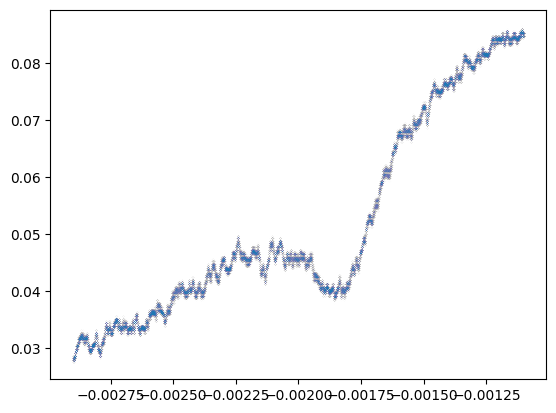

In [5]:

# filepath = "500.csv"

# #select side 1,2,3, or 4
# side = "4"

data = pd.read_csv(filepath)


# Set t range to cut off when ramp flips direction
t_min, t_max = -np.inf, np.inf
if side == "n":
    t_min, t_max = -np.inf, np.inf
elif side == "1":
    t_min, t_max = -0.0029, -0.0011
elif side =="2":
    t_min, t_max = -0.001, 0.001
elif side =="3":
    t_min, t_max = 0.001, 0.003
elif side == "4":
    t_min, t_max = 0.0031, 0.005

    
data_filtered = data[(data['Time(s)'] >= t_min) & (data['Time(s)'] <= t_max)]

t = data_filtered['Time(s)']
CH2 = data_filtered["CH2(V)"]

plt.plot(t,CH2, markersize = 0.005, linestyle = "None", marker = ".")

0.0014198991710294496


<function matplotlib.pyplot.show(close=None, block=None)>

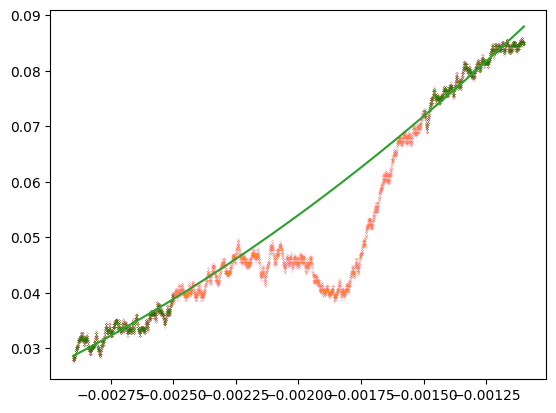

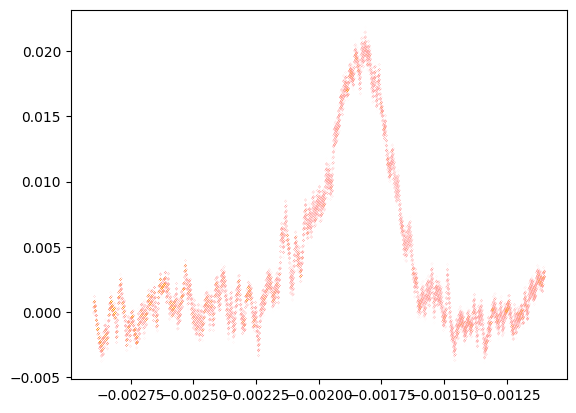

In [6]:
#filter data to not include the peaks 
if side == "1":
    t_remove_min, t_remove_max = -0.0025, -0.0015
elif side =="2":
    t_remove_min, t_remove_max = -0.00055, 0.0005
elif side =="3":
    t_remove_min, t_remove_max = 0.0016, 0.0027
elif side == "4":
    t_remove_min, t_remove_max = 0.0035, 0.0045
    

data_subtrac_ramp = data_filtered[(data_filtered['Time(s)'] < t_remove_min) | (data_filtered['Time(s)'] > t_remove_max)]

t_ramp = data_subtrac_ramp['Time(s)']
CH2_ramp = data_subtrac_ramp["CH2(V)"]

#do polynomial fit
coeffs = np.polyfit(t_ramp,CH2_ramp, deg = 2)
ramp = np.polyval(coeffs,t)

#get estimate for noise error
resid = CH2_ramp - np.polyval(coeffs,t_ramp)
dof = len(t_ramp) - 3 #quadratic fit
sigma_y = np.sqrt(np.sum(resid**2)/dof) #rms noise
print(sigma_y)

plt.figure()
plt.plot(t_ramp,CH2_ramp, markersize = 0.005, linestyle = "None", marker = ".")
plt.plot(t,CH2, markersize = 0.005, linestyle = "None", marker = ".")
plt.plot(t,ramp)
plt.show

# subtract the ramp from data

Rb_spectrum = - (CH2 - ramp)
plt.figure()
plt.plot(t, Rb_spectrum, markersize = 0.005, linestyle = "None", marker = ".", color = "orange")
plt.show

0.021397027742162112,1.4456857303476744e-05


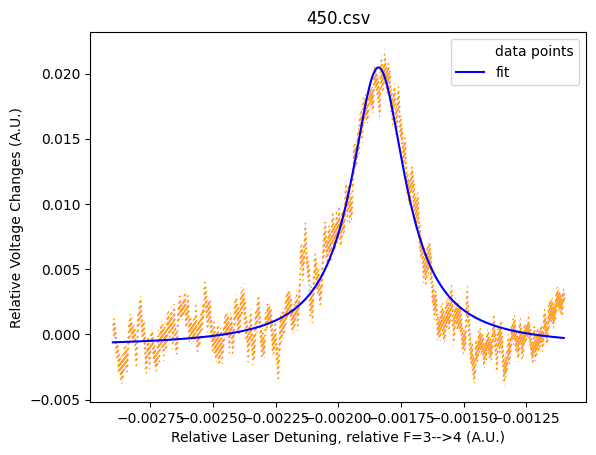

In [7]:
#def lorentzian 
def lorentz(x,G):
    return 1.0 / (1.0 + (x / (G/2.0))**2)

def model_function(x,G,scale,dx,offset):
    return scale*lorentz(x-dx,G)+offset

# initial guesses
if side == "1":
    dx_guess = -0.0019
elif side == "2":
    dx_guess = -0.0001
elif side =="3":
    dx_guess = 0.0021
elif side =="4":
    dx_guess = 0.0041

H_guess = np.nanmax(Rb_spectrum) - np.nanmedian(Rb_spectrum)  # rough

p0 = [2.0e-4, H_guess, dx_guess, 0.0]
lb = [1e-12, 0.0, -np.inf, -np.inf]  # G>0, H>=0
ub = [9.5e-3,  np.inf,  np.inf,  np.inf]

popt, pcov = curve_fit(
    model_function, t, Rb_spectrum,
    p0=p0, sigma=sigma_y, absolute_sigma=True,
    bounds=(lb, ub), method="trf", maxfev= 1000
)


#get fits
G, scale, dx,offset = popt
eG, escale,edx,eoffset = np.sqrt(np.diag(pcov))

# create best fit data
y_fit = model_function(t, *popt)

# get reduced chi^2
residual = Rb_spectrum - y_fit
chi_squared = np.sum((residual / sigma_y) ** 2)
dof = len(t) - len(popt)
chi_squared_reduced = chi_squared / dof

fig, ax = plt.subplots()
ax.plot(t, Rb_spectrum, markersize = 0.05, linestyle = "None", marker = "x",color = "orange", label = "data points")
ax.plot(t,y_fit, label ="fit", color = "blue")
ax.set_xlabel("Relative Laser Detuning, relative F=3-->4 (A.U.)")
ax.set_ylabel("Relative Voltage Changes (A.U.)")
ax.set_title(filepath)
ax.legend(loc='best')


pyperclip.copy(f"{scale},")
print(f"{scale},{escale}")